# Rice leaf blast detection with the authors' released InceptionV3 model

**Paper:** Syed Rehan Shah, Salman Qadri, Hadia Bibi, Syed Muhammad Waqas Shah, Muhammad Imran Sharif, Francesco Marinello,
*Comparing Inception V3, VGG 16, VGG 19, CNN, and ResNet 50: A Case Study on Early Detection of a Rice Disease*,
**Agronomy 13(6):1633 (2023)**, [DOI 10.3390/agronomy13061633](https://doi.org/10.3390/agronomy13061633)

**Purpose:** run pretrained inference with the authors' released Keras weights (`INCEPTIONV#.h5` from their Hugging Face Space)
on real rice-leaf images from the paper-cited Kaggle dataset, following the authors' Gradio `app.py` as far as it is defined.

**Scope (partial demonstration, inference only):** one of the five architectures (InceptionV3, the only one with released
weights), a small deterministic image sample, and raw two-class probability outputs. This notebook does **not** retrain,
does not compare the five architectures, and does not verify the paper's reported accuracies (e.g., 99.75%).

**Documented discrepancies and unknowns** (from the authors' own artifacts — see the interpretation section):

- The released model expects **256×256** input (printed below). The served `app.py` reshapes to **224×224**, which is
  incompatible with the released weights (the app as served would raise a shape error). This notebook follows the model.
- `app.py` references `model` and `class_names` but **never defines them**; the class-name strings and the output-index
  order are **not recoverable** from the authors' artifacts. Outputs are reported as *class 0 / class 1*.
- `app.py` applies **no explicit input normalization**, and the model file contains no embedded rescaling layer. The
  authors' true training normalization is unknown, so this notebook executes the inference under **three explicit
  preprocessing variants** (raw uint8 — the literal `app.py` path, /255, and Keras InceptionV3 `preprocess_input`) and
  reports the sensitivity of the result to that unknown choice.
- The paper-cited Kaggle dataset (`shareef0612/riceleaf-dataset`) contains 4 disease classes (Blast, Bacterialblight,
  Brownspot, Tungro; per-class file counts printed when downloaded) and **no healthy class**, while the paper describes a
  1200-blast/800-healthy binary set. Only the released 2-class model and this cited dataset are available, so they are
  used as-is.

**AI-assisted glue notice / AI補助による実装:** *The inference glue in this notebook (download/verify/preprocess/predict
cells) was written for this reproduction following the authors' `app.py`; the authors did not provide a runnable
inference script. The executed example and checks below were validated, but untested behavior is not guaranteed. /
本ノートブックの推論用コードは著者の `app.py` に沿って本 reproduction 用に作成したものであり、著者提供の実行スクリプトではありません。*

**日本語要約:** 著者が公開したイネいもち病検出モデル（InceptionV3, Keras重み）を論文引用のKaggleデータセットの実画像で
推論する最小デモです。学習・5モデル比較・論文の精度検証は範囲外です。著者成果物から復元できない情報（入力前処理、
クラス名と出力順）は、複数の候補前処理での感度比較として明示的に示します。

## Runtime selection

**Select Runtime → Change runtime type → CPU (recommended).** This demo is single-batch inference on ~20 small
images; a GPU is unnecessary and the authors' own Gradio app runs on CPU. The notebook is device-agnostic (TensorFlow
reports any visible GPU below) but was validated on a fresh Colab **CPU** runtime.

**Run all:** Runtime → Run all. Expected: ~290 MiB downloads (196 MiB Kaggle dataset + 90 MB weights), a few minutes
total on the free tier. / **ランタイム:** CPU を推奨（単発推論のため GPU 不要）。Run all で数分・約290MiBのダウンロードです。

In [ ]:
import sys
print("Python:", sys.version.split()[0])
import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU devices visible to TensorFlow:", gpus if gpus else "none (CPU runtime) - expected and sufficient for this demo")
import numpy as np, matplotlib, pandas as pd
from PIL import Image
print("NumPy:", np.__version__, "| matplotlib:", matplotlib.__version__, "| pandas:", pd.__version__)

Python: 3.13.18


TensorFlow: 2.21.0
GPU devices visible to TensorFlow: none (CPU runtime) - expected and sufficient for this demo
NumPy: 2.1.3 | matplotlib: 3.10.0 | pandas: 2.2.3


## 1. Dataset acquisition

The paper cites the public Kaggle dataset `shareef0612/riceleaf-dataset` (reference 37). It is downloaded with
`kagglehub`, which fetches public Kaggle datasets anonymously (no login/token). The cell prints the actual directory
structure, per-class file counts, and total size — the dataset inventory is disclosed from the actual download, not
assumed. / 論文引用のKaggleデータセットを `kagglehub` で匿名ダウンロードし、実際の構成・クラス数・サイズを表示します。

In [ ]:
%pip install -q kagglehub
import kagglehub
print("kagglehub", kagglehub.__version__)

kagglehub 1.0.3


Download the dataset and summarize its structure. All dataset bytes stay on the Colab VM (`/content` / kagglehub cache).

In [ ]:
from pathlib import Path
ds_path = Path(kagglehub.dataset_download("shareef0612/riceleaf-dataset"))
print("downloaded to:", ds_path)
total = sum(f.stat().st_size for f in ds_path.rglob("*") if f.is_file())
print(f"total size: {total/2**20:.1f} MiB")
img_root = ds_path / "Rice Leaf Disease Images"
classes = sorted(d.name for d in img_root.iterdir() if d.is_dir())
class_counts = {c: len(list((img_root / c).glob("*.jpg"))) for c in classes}
for c in classes:
    print(f"  {c:16s} {class_counts[c]:5d} jpg files")
assert set(class_counts) >= {"Blast"}, "expected a Blast class in the cited dataset"
print("classes:", classes)

  0%|          | 0.00/196M [00:00<?, ?B/s]

  4%|▎         | 7.00M/196M [00:00<00:03, 60.8MB/s]

 13%|█▎        | 26.0M/196M [00:00<00:01, 133MB/s] 

 23%|██▎       | 45.0M/196M [00:00<00:00, 159MB/s]

 33%|███▎      | 64.0M/196M [00:00<00:00, 174MB/s]

 42%|████▏     | 83.0M/196M [00:00<00:00, 180MB/s]

... (5 outputs left out)

 95%|█████████▌| 186M/196M [00:01<00:00, 161MB/s]

100%|██████████| 196M/196M [00:01<00:00, 163MB/s]

Extracting files...


downloaded to: /root/.cache/kagglehub/datasets/shareef0612/riceleaf-dataset/versions/1
total size: 198.0 MiB
  Bacterialblight   1326 jpg files
  Blast              918 jpg files
  Brownspot         1600 jpg files
  Tungro             424 jpg files
classes: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


## 2. Model weights acquisition with checksum verification

The authors' Hugging Face Space `Rehan2785/Rice_Leaf_Blast` (pinned revision `8722c3c1ea76748d64b5ec4ec8da5ce5043e561d`,
last modified 2022-08-04, license AFL-3.0) contains the Keras weight file `INCEPTIONV#.h5`. Its Git LFS metadata pins
SHA-256 `95daa998…3cc` and size 89,862,328 bytes. The cell downloads the file into `/content` and **verifies both**,
rejecting any LFS pointer text or error page. / 著者のHF Spaceから重み(90MB)をダウンロードし、LFSメタデータのSHA-256と
サイズを検証します（失敗時は例外で停止）。

In [ ]:
import hashlib, requests
WEIGHTS_URL = "https://huggingface.co/spaces/Rehan2785/Rice_Leaf_Blast/resolve/main/INCEPTIONV%23.h5"
WEIGHTS_SHA256 = "95daa99844eb8891cdef9ac452a7dfcebb2e06720eaa074fc032e2ee375ee3cc"
WEIGHTS_SIZE = 89_862_328
weights_path = Path("/content/INCEPTIONV_sharp.h5")  # '#' in the original name is URL-encoded; local name keeps it simple
if not weights_path.exists() or weights_path.stat().st_size != WEIGHTS_SIZE:
    with requests.get(WEIGHTS_URL, timeout=600, stream=True) as r:
        r.raise_for_status()
        with open(weights_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
data = weights_path.read_bytes()
assert len(data) == WEIGHTS_SIZE, f"unexpected size: {len(data)}"
assert not data.startswith(b"version https://git-lfs"), "downloaded an LFS pointer, not weights"
digest = hashlib.sha256(data).hexdigest()
assert digest == WEIGHTS_SHA256, f"checksum mismatch: {digest}"
print("weights OK:", weights_path.name, len(data), "bytes, sha256", digest)

weights OK: INCEPTIONV_sharp.h5 89862328 bytes, sha256 95daa99844eb8891cdef9ac452a7dfcebb2e06720eaa074fc032e2ee375ee3cc


## 3. Load the released model and inspect it

This reproduces `app.py` line 3 (`from tensorflow.keras.models import load_model`) against the actual released file.
The printed input shape is the **observed** expectation of these weights — the diagnostic basis for using 256×256
instead of `app.py`'s 224×224 reshape. The cell also verifies whether any rescaling layer is embedded (it is not),
which motivates the preprocessing sensitivity analysis below. / `app.py` と同様に `load_model` で読み込み、入力形状と
埋め込み前処理層の有無を確認します（リリース済み重みは 256×256 を期待します）。

In [ ]:
from tensorflow.keras.models import load_model
model = load_model(str(weights_path))
print("input_shape:", model.input_shape)
print("output_shape:", model.output_shape)
out_layer = model.layers[-1]
print("output layer:", out_layer.name, type(out_layer).__name__, "activation:", out_layer.activation.__name__)
rescalers = [l.name for l in model.layers if "rescal" in type(l).__name__.lower() or "normalization" == type(l).__name__.lower()]
print("embedded rescaling/normalization layers (excl. BatchNorm):", rescalers if rescalers else "none")
print("n top-level layers:", len(model.layers))

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


input_shape: (None, 256, 256, 3)
output_shape: (None, 2)
output layer: dense Dense activation: softmax
embedded rescaling/normalization layers (excl. BatchNorm): none
n top-level layers: 313


## 4. Deterministic minimal sample

A fixed, reproducible selection: the **first 8 alphabetically sorted** images of the `Blast` class (the paper's target
disease) plus the first 4 of each other class as context. Filenames are printed so any reader can rerun the exact
sample. No cherry-picking by results. / 最小サンプルは各クラスのソート先頭から決定的に選択します（結果による選別なし）。

In [ ]:
samples = []  # (reference_label, Path) in deterministic order
for c in classes:
    n = 8 if c == "Blast" else 4
    samples += [(c, p) for p in sorted((img_root / c).glob("*.jpg"))[:n]]
print("selected", len(samples), "images:",
      {c: sum(1 for l, _ in samples if l == c) for c in classes})
print("first Blast files:", [p.name for l, p in samples if l == "Blast"][:3], "...")

selected 20 images: {'Bacterialblight': 4, 'Blast': 8, 'Brownspot': 4, 'Tungro': 4}
first Blast files: ['BLAST1_001.jpg', 'BLAST1_002.jpg', 'BLAST1_003.jpg'] ...


## 5. Input preview (reference labels from the dataset folders)

Each panel shows an actual downloaded image titled with its reference class label — the dataset's own folder name, i.e.
the dataset's real annotation, not a model output. Blast rows are the demonstration inputs; other classes provide
visual context. / ダウンロードした実画像を、データセットフォルダ名（参照ラベル）付きで表示します。これはモデル出力では
なくデータセット側のアノテーションです。

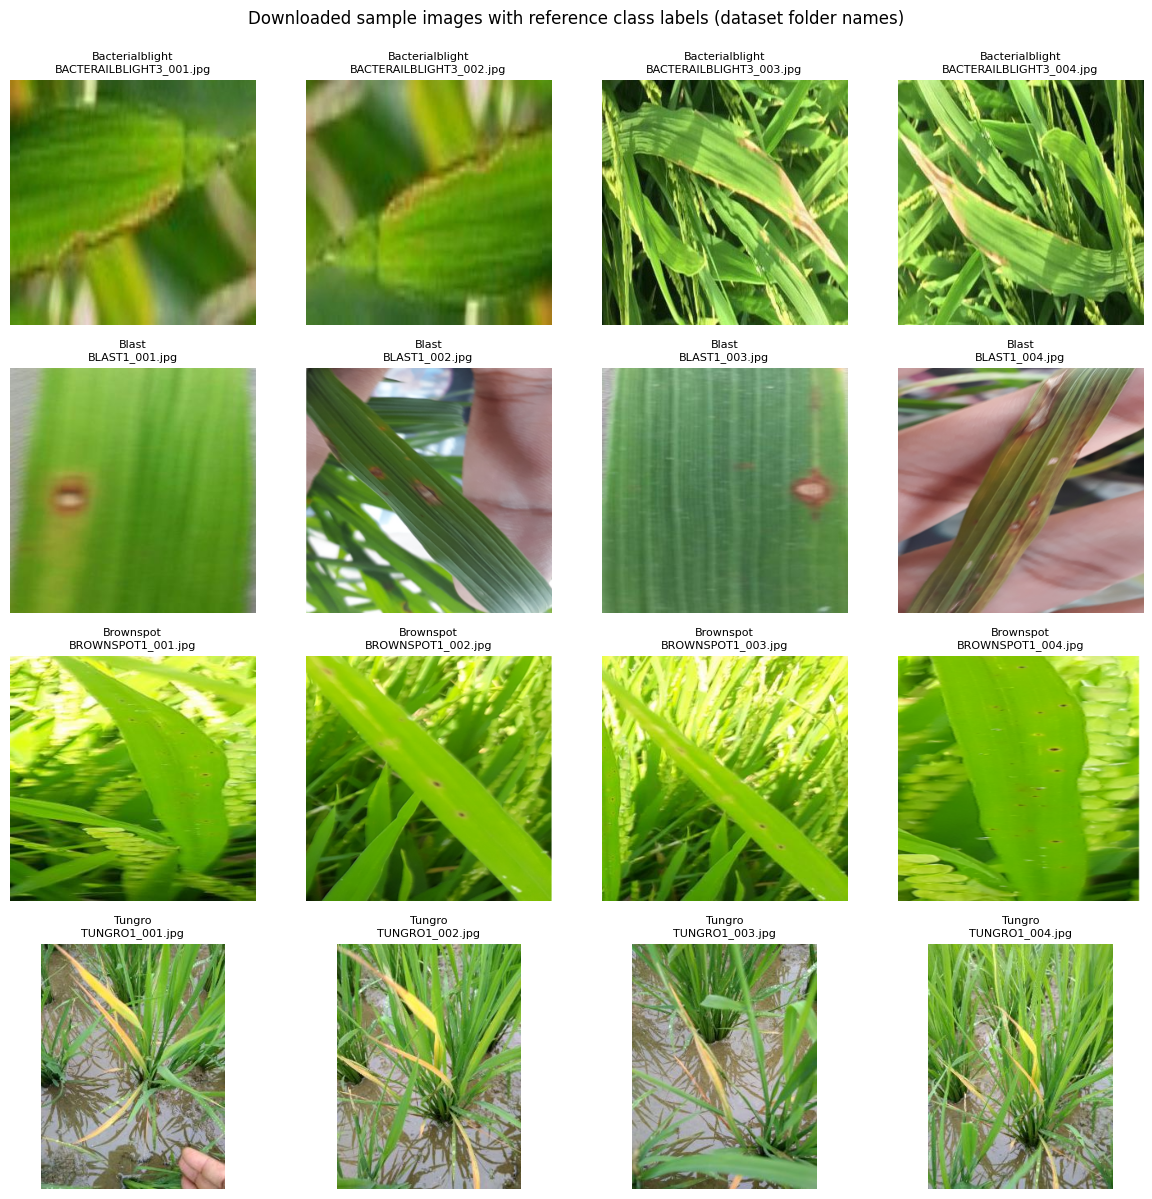

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
shown = {}
for label, p in samples:
    if shown.get(label, 0) >= 4:
        continue
    ax = axes[classes.index(label), shown.get(label, 0)]
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(f"{label}\n{p.name}", fontsize=8)
    ax.axis("off")
    shown[label] = shown.get(label, 0) + 1
for row in axes:
    for ax in row:
        if not ax.images:
            ax.axis("off")
fig.suptitle("Downloaded sample images with reference class labels (dataset folder names)", y=0.995)
fig.tight_layout()
plt.show()

## 6. Inference under three explicit preprocessing variants

`app.py` performs no normalization: its literal path is `img.reshape(-1,224,224,3)` on a PIL-resized uint8 image. We
reproduce that **structure** but (a) resize to the released model's actual 256×256 input and (b) run three explicit
variants, because the authors' training normalization is not recorded in any available artifact:

1. `raw_uint8` — the literal `app.py` path (uint8 0–255, no scaling);
2. `divide_255` — 0–1 scaling (a common Keras default);
3. `inception_pp` — `tf.keras.applications.inception_v3.preprocess_input` (scales to [−1,1]; the standard InceptionV3 recipe).

Predictions are the raw softmax outputs mapped exactly as `app.py` line 12 would (`{class_names[i]: p[i]}`), with
index labels used because the authors' `class_names` list is not recoverable. / 著者の前処理は記録がないため、3種類の
候補前処理で同じモデル推論を実行し、結果の感度を比較します（出力は class 0 / class 1 の生ソフトマックス値）。

In [ ]:
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_pp

def load_256(p):
    return np.asarray(Image.open(p).convert("RGB").resize((256, 256)))  # PIL default resampling

def predict_image(img_4d):
    # structure follows app.py: model.predict(batch)[0]; index mapping would be {class_names[i]: p[i]}
    pred = model.predict(img_4d, verbose=0)[0]
    return {f"class_{i}": float(pred[i]) for i in range(pred.shape[0])}

variants = {
    "raw_uint8": lambda a: a.reshape(-1, 256, 256, 3),
    "divide_255": lambda a: (a / 255.0).astype("float32").reshape(-1, 256, 256, 3),
    "inception_pp": lambda a: inception_pp(a.astype("float32")).reshape(-1, 256, 256, 3),
}
rows = []
for label, p in samples:
    arr = load_256(p)
    for vname, prep in variants.items():
        probs = predict_image(prep(arr))
        rows.append({"reference_class": label, "file": p.name,
                     "variant": vname,
                     "p_class0": probs["class_0"], "p_class1": probs["class_1"],
                     "argmax_index": int(np.argmax([probs["class_0"], probs["class_1"]]))})
results = pd.DataFrame(rows)
print(f"ran {len(rows)} inferences ({len(samples)} images x {len(variants)} variants)")
results.head(6)

ran 60 inferences (20 images x 3 variants)


,reference_class,file,variant,p_class0,p_class1,argmax_index
0,Bacterialblight,BACTERAILBLIGHT3_001.jpg,raw_uint8,0.000000,1.000000e+00,1
1,Bacterialblight,BACTERAILBLIGHT3_001.jpg,divide_255,1.000000,1.889205e-07,0
2,Bacterialblight,BACTERAILBLIGHT3_001.jpg,inception_pp,1.000000,1.705306e-08,0
3,Bacterialblight,BACTERAILBLIGHT3_002.jpg,raw_uint8,0.000000,1.000000e+00,1
4,Bacterialblight,BACTERAILBLIGHT3_002.jpg,divide_255,0.823244,1.767559e-01,0
5,Bacterialblight,BACTERAILBLIGHT3_002.jpg,inception_pp,0.999961,3.911439e-05,0


## 7. Sensitivity of the prediction to the unknown preprocessing

The chart shows, for every sampled image (grouped by reference class), the model's class-0 probability under each
preprocessing variant. Because the authors' true normalization is unknown and `class_names` is undefined, this graph
is a **diagnostic of that ambiguity** — an additional visualization created for this notebook, not an author figure and
not a reproduced paper result. / 前処理の不確実性が予測に与える影響を、クラス別・バリアント別の棒グラフで可視化します
（このノートブック用の追加可視化であり、論文図の再現ではありません）。

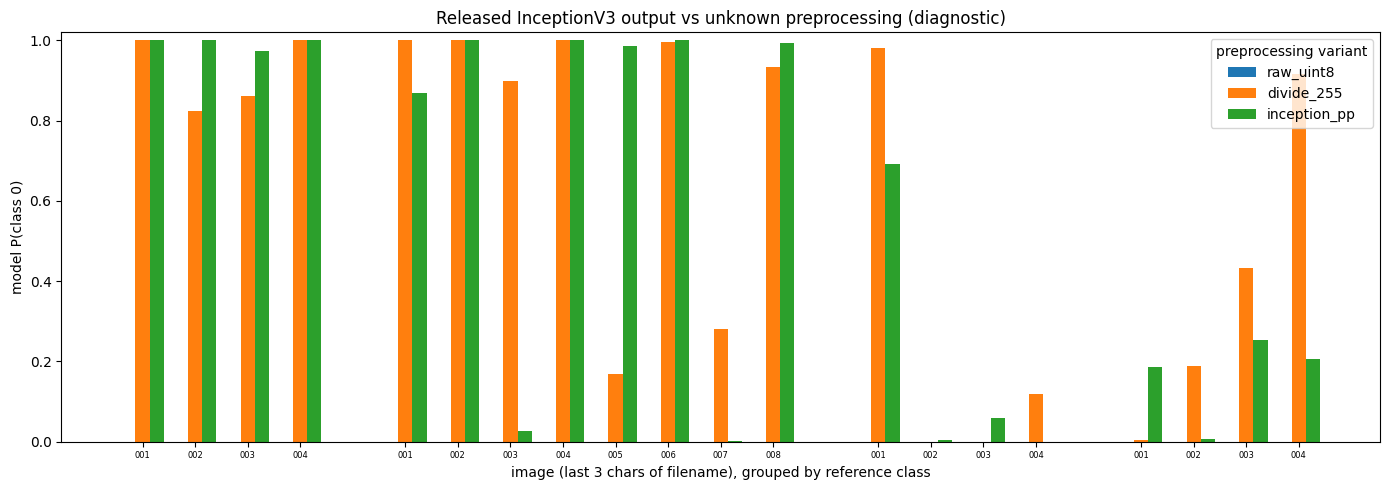

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
xpos, xlabels = [], []
x = 0
for c in classes:  # one x slot per image, shared by the three variant bars
    files = sorted(results[results.reference_class == c].file.unique())
    xpos.extend(range(x, x + len(files)))
    xlabels.extend([f.split(".")[0][-3:] for f in files])
    x += len(files) + 1
width = 0.27
for i, v in enumerate(variants):
    vals = []
    for c in classes:
        sub = results[(results.reference_class == c) & (results.variant == v)].sort_values("file")
        vals.extend(sub.p_class0.tolist())
    ax.bar([t + (i - 1) * width for t in xpos], vals, width=width, label=v)
ax.set_xticks(xpos)
ax.set_xticklabels(xlabels, fontsize=6)
ax.set_ylabel("model P(class 0)")
ax.set_xlabel("image (last 3 chars of filename), grouped by reference class")
ax.set_title("Released InceptionV3 output vs unknown preprocessing (diagnostic)")
ax.legend(title="preprocessing variant")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

## 8. Representative input with model output overlay

The first (alphabetically) Blast image is shown with the model's two-class output for each preprocessing variant in
the panel title. Output indices are labeled `class_0/class_1` because the authors' class-name list is not recoverable
from their artifacts. / 代表的なBlast画像に、各前処理バリアントでのモデル出力（class_0/class_1）を重ねて表示します。
クラス名は著者成果物から復元できないため添字で示します。

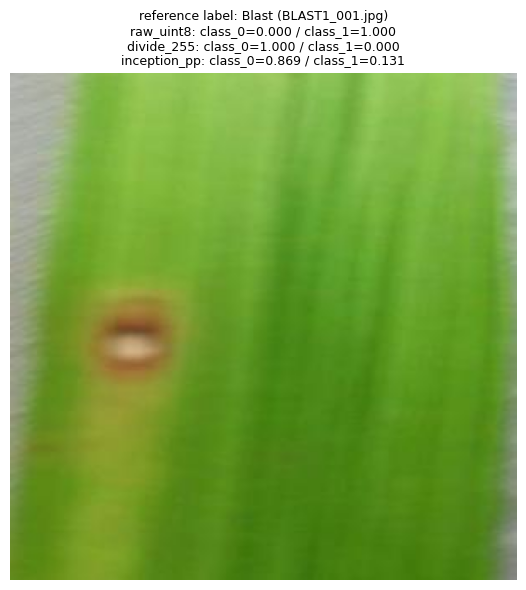

In [ ]:
rep_label, rep_path = next((l, p) for l, p in samples if l == "Blast")
rep_arr = load_256(rep_path)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(Image.open(rep_path).convert("RGB"))
title = f"reference label: {rep_label} ({rep_path.name})\n"
for vname, prep in variants.items():
    probs = predict_image(prep(rep_arr))
    title += f"{vname}: class_0={probs['class_0']:.3f} / class_1={probs['class_1']:.3f}\n"
ax.set_title(title.strip(), fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Interpretation and limitations

**What this demo establishes (observed in this run):** the authors' released `INCEPTIONV#.h5` loads on current Colab
TensorFlow, expects 256×256×3 input, and produces a 2-way softmax output; the paper-cited Kaggle dataset is real and
its `Blast` class provides valid demonstration inputs; the served `app.py` preprocessing path (224×224) is incompatible
with the released weights.

**What remains unverified / unknown:**

- **Class names and output-index order** — `app.py` uses an undefined `class_names`; no available artifact records the
  mapping. Outputs are therefore reported as `class_0`/`class_1` only. The empirical behavior across classes varies
  with preprocessing and does not permit a reliable inference of the mapping (see the sensitivity graph).
- **Training normalization** — no recorded value; the three variants shown give materially different, sometimes
  saturated outputs, so no single number above should be read as "the" prediction.
- **Healthy images** — the cited Kaggle dataset contains no healthy class, so the paper's 1200-blast/800-healthy
  protocol cannot be checked against it.
- **All training-side claims** (99.75% accuracy for modified ResNet50, 98.16–98.56% for the others, validation metrics)
  are out of scope and unverified here; the other four architectures have no released weights.

**日本語:** 著者公開重みは256×256入力で現在のColabでも動作し、引用データセットのBlast画像で推論できます。ただし
クラス名・出力順・学習時の前処理は記録がなく、前処理候補によって出力が大きく変わるため、単一の「正解予測」とは
解釈できません。学習精度の検証は範囲外です。

## 10. Results export

The per-image, per-variant prediction table is written to CSV on the Colab VM so a reader can inspect or download it. /
結果表をColab VM上のCSVに保存します。

In [ ]:
csv_path = Path("/content/rice_blast_inference_results.csv")
results.to_csv(csv_path, index=False)
print("saved:", csv_path, f"({len(results)} rows)")
results

saved: /content/rice_blast_inference_results.csv (60 rows)


,reference_class,file,variant,p_class0,p_class1,argmax_index
0,Bacterialblight,BACTERAILBLIGHT3_001.jpg,raw_uint8,0.000000,1.000000e+00,1
1,Bacterialblight,BACTERAILBLIGHT3_001.jpg,divide_255,1.000000,1.889205e-07,0
2,Bacterialblight,BACTERAILBLIGHT3_001.jpg,inception_pp,1.000000,1.705306e-08,0
3,Bacterialblight,BACTERAILBLIGHT3_002.jpg,raw_uint8,0.000000,1.000000e+00,1
4,Bacterialblight,BACTERAILBLIGHT3_002.jpg,divide_255,0.823244,1.767559e-01,0
5,Bacterialblight,BACTERAILBLIGHT3_002.jpg,inception_pp,0.999961,3.911439e-05,0
6,Bacterialblight,BACTERAILBLIGHT3_003.jpg,raw_uint8,0.000000,1.000000e+00,1
7,Bacterialblight,BACTERAILBLIGHT3_003.jpg,divide_255,0.860783,1.392175e-01,0
8,Bacterialblight,BACTERAILBLIGHT3_003.jpg,inception_pp,0.972534,2.746553e-02,0
9,Bacterialblight,BACTERAILBLIGHT3_004.jpg,raw_uint8,0.000000,1.000000e+00,1


## Validation record and references

- **Validated:** fresh Google Colab **CPU** runtime (single top-to-bottom run of this notebook; see the archived
  `*_output.ipynb` for the executed outputs of this exact source). Hardware and library versions are printed in the
  outputs above. / 本ノートブックは新しいColab CPUランタイムで先頭から末尾まで1回実行・検証されました。
- **Author code:** `app.py` (Hugging Face Space `Rehan2785/Rice_Leaf_Blast`, revision `8722c3c1ea76748d64b5ec4ec8da5ce5043e561d`,
  blob `bd8e1ed5`), license AFL-3.0; weights `INCEPTIONV#.h5` SHA-256 `95daa99844eb8891cdef9ac452a7dfcebb2e06720eaa074fc032e2ee375ee3cc`.
- **Dataset:** `shareef0612/riceleaf-dataset` (Kaggle, version 1; size and per-class counts as printed in the outputs
  above), cited as reference 37 of the paper (Crossref record 10.3390/agronomy13061633).
- **Paper:** Agronomy 13(6):1633 (2023), DOI 10.3390/agronomy13061633 (abstract-level metadata; publisher full text
  returned HTTP 403 to automated retrieval and the OpenAlex content budget was exhausted — training-protocol details
  were therefore not read, and none are needed for this inference-only scope).
- **GUI → code mapping:** `gr.inputs.Image(shape=(224,224))` → PIL resize to the model's actual 256×256; `predict_image`
  reshape/predict → `predict_image` above; `gr.outputs.Label` → printed/DataFrame outputs; web UI launch is omitted.